# APOGEE and HARPS linear abundance-ratio trends with [Fe/H]

This notebook compares APOGEE and HARPS linear abundance ratios as a function of $[\mathrm{Fe/H}]$.

It does the following:

- loads `apogee_sample.csv` and `harps_sample.csv`
- applies the same cleaning cuts used in the ML notebook
- computes the linear absolute ratios `Fe/Si`, `Mg/Si`, `C/O`, and `Fe/O`
- fits a straight line separately to APOGEE and HARPS for each ratio
- estimates slope and intercept uncertainties with bootstrap resampling
- reports one global RMS scatter around each best-fit line
- overlays APOGEE and HARPS scatter plots in one panel with shared y-axis scaling

The linear ratios use the adopted solar abundances:

- `C = 8.46`
- `O = 8.69`
- `Mg = 7.55`
- `Si = 7.51`
- `Fe = 7.46`


In [21]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-white")
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "figure.dpi": 200,
})

APOGEE_COLOR = "#1f77b4"
HARPS_COLOR = "#ff7f0e"
APOGEE_ALPHA = 0.1
HARPS_ALPHA = 0.5
FIT_LINEWIDTH = 4.0
BOOTSTRAP_SAMPLES = 500
RANDOM_SEED = 42
OUTPUT_DIR = Path("figures/ratio_fits")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [22]:
SOLAR_ABUNDANCES = {
    "c": 8.46,
    "o": 8.69,
    "mg": 7.55,
    "si": 7.51,
    "fe": 7.46,
}

RATIO_SPECS = {
    "fe_si": {
        "label": "Fe/Si",
        "numerator": "fe",
        "denominator": "si",
        "num_col": "fe_h",
        "den_col": "si_h",
        "ylim": (0.2, 1.2),
    },
    "mg_si": {
        "label": "Mg/Si",
        "numerator": "mg",
        "denominator": "si",
        "num_col": "mg_h",
        "den_col": "si_h",
        "ylim": (0.5, 1.8),
    },
    "c_o": {
        "label": "C/O",
        "numerator": "c",
        "denominator": "o",
        "num_col": "c_h",
        "den_col": "o_h",
        "ylim": (0.0, 1.0),
    },
    "fe_o": {
        "label": "Fe/O",
        "numerator": "fe",
        "denominator": "o",
        "num_col": "fe_h",
        "den_col": "o_h",
        "ylim": (0.0, 0.1),
    },
}

PRETTY_LABELS = {
    "fe_h": r"$[\mathrm{Fe/H}]$",
    "linear": {
        "fe_si": "Fe/Si",
        "mg_si": "Mg/Si",
        "c_o": "C/O",
        "fe_o": "Fe/O",
    },
}


## Load and clean data

In [23]:
def clean_survey_data(df, survey_name):
    df = df.copy()
    df = df[df["parallax"] > 0.0]
    df["rel_parallax"] = df["parallax_error"] / df["parallax"]
    df = df[df["rel_parallax"] < 0.1]

    if survey_name.lower() == "apogee":
        df = df[df["logg"] < 3]

    df = df[df["zmax"] < 10]
    return df


apogee = pd.read_csv("apogee_sample.csv")
harps = pd.read_csv("harps_sample.csv")

print(f"Raw APOGEE rows: {len(apogee)}")
print(f"Raw HARPS rows:  {len(harps)}")

apogee = clean_survey_data(apogee, "apogee")
harps = clean_survey_data(harps, "harps")

print(f"Clean APOGEE rows: {len(apogee)}")
print(f"Clean HARPS rows:  {len(harps)}")


Raw APOGEE rows: 95586
Raw HARPS rows:  798
Clean APOGEE rows: 45727
Clean HARPS rows:  798


## Build linear ratios

In [24]:
def add_linear_ratio_columns(df):
    df = df.copy()

    for key, spec in RATIO_SPECS.items():
        log_ratio = df[spec["num_col"]] - df[spec["den_col"]]
        solar_offset = SOLAR_ABUNDANCES[spec["numerator"]] - SOLAR_ABUNDANCES[spec["denominator"]]
        df[f"linear_{key}"] = 10 ** (log_ratio + solar_offset)

    return df


apogee = add_linear_ratio_columns(apogee)
harps = add_linear_ratio_columns(harps)

ratio_columns = [f"linear_{key}" for key in RATIO_SPECS]
apogee[["fe_h"] + ratio_columns].head()


,fe_h,linear_fe_si,linear_mg_si,linear_c_o,linear_fe_o
2,-0.08,0.870964,1.071519,0.346737,0.053703
3,-0.28,0.851138,1.258925,0.363078,0.046774
6,-0.26,0.676083,1.071519,0.181970,0.053703
7,0.05,0.891251,1.230269,0.467735,0.051286
8,0.03,0.741310,1.071519,0.512861,0.052481


## Fit and plotting helpers

In [25]:
def prepare_fit_data(df, y_col):
    cols = ["fe_h", y_col]
    fit_df = df[cols].replace([np.inf, -np.inf], np.nan).dropna().copy()
    fit_df = fit_df.sort_values("fe_h")
    return fit_df


def best_fit_line(x, y):
    slope, intercept = np.polyfit(x, y, 1)
    return float(slope), float(intercept)


def bootstrap_linear_fit(x, y, n_bootstrap=BOOTSTRAP_SAMPLES, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    n = len(x)
    slopes = np.empty(n_bootstrap, dtype=float)
    intercepts = np.empty(n_bootstrap, dtype=float)

    for i in range(n_bootstrap):
        idx = rng.integers(0, n, n)
        slope_i, intercept_i = np.polyfit(x[idx], y[idx], 1)
        slopes[i] = slope_i
        intercepts[i] = intercept_i

    return slopes, intercepts


def fit_linear_relation(x, y, n_bootstrap=BOOTSTRAP_SAMPLES, seed=RANDOM_SEED):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    slope, intercept = best_fit_line(x, y)
    y_fit = slope * x + intercept
    residuals = y - y_fit
    rms_scatter = float(np.sqrt(np.mean(residuals ** 2)))
    r_value = float(np.corrcoef(x, y)[0, 1]) if len(x) > 1 else np.nan

    boot_slopes, boot_intercepts = bootstrap_linear_fit(
        x,
        y,
        n_bootstrap=n_bootstrap,
        seed=seed,
    )

    return {
        "slope": slope,
        "intercept": intercept,
        "slope_err": float(np.std(boot_slopes, ddof=1)),
        "intercept_err": float(np.std(boot_intercepts, ddof=1)),
        "rms_scatter": rms_scatter,
        "r": r_value,
    }


def format_equation(fit_result, x_label="[Fe/H]"):
    return (
        f"y = ({fit_result['intercept']:.4f} +/- {fit_result['intercept_err']:.4f}) + "
        f"({fit_result['slope']:.4f} +/- {fit_result['slope_err']:.4f}) * {x_label}"
    )


def plot_ratio_fits(apogee_df, harps_df, ratio_key, save_dir=OUTPUT_DIR):
    y_col = f"linear_{ratio_key}"
    y_label = PRETTY_LABELS["linear"][ratio_key]
    ratio_label = RATIO_SPECS[ratio_key]["label"]
    y_limits = RATIO_SPECS[ratio_key]["ylim"]

    datasets = [
        ("APOGEE", apogee_df, APOGEE_COLOR, APOGEE_ALPHA),
        ("HARPS", harps_df, HARPS_COLOR, HARPS_ALPHA),
    ]

    fig, ax = plt.subplots(1, 1, figsize=(7.2, 4.8))
    fit_rows = []

    for idx, (survey_name, df, color, alpha) in enumerate(datasets):
        fit_df = prepare_fit_data(df, y_col)
        x = fit_df["fe_h"].to_numpy()
        y = fit_df[y_col].to_numpy()
        fit_result = fit_linear_relation(x, y)

        x_line = np.linspace(x.min(), x.max(), 200)
        y_line = fit_result["slope"] * x_line + fit_result["intercept"]

        scatter_zorder = 1 + idx
        line_zorder = 4 + idx
        ax.scatter(x, y, s=14, alpha=alpha, color=color, edgecolor="none", zorder=scatter_zorder)
        ax.plot(x_line, y_line, color=color, lw=FIT_LINEWIDTH, zorder=line_zorder, label=f"{survey_name}")

        fit_rows.append({
            "survey": survey_name,
            "ratio_key": ratio_key,
            "ratio": ratio_label,
            "n_stars": len(fit_df),
            "intercept": fit_result["intercept"],
            "intercept_err": fit_result["intercept_err"],
            "slope": fit_result["slope"],
            "slope_err": fit_result["slope_err"],
            "rms_scatter": fit_result["rms_scatter"],
            "r": fit_result["r"],
            "equation": format_equation(fit_result),
        })

    ax.set_xlabel(PRETTY_LABELS["fe_h"])
    ax.set_ylabel(y_label)
    ax.set_ylim(*y_limits)
    #ax.set_title(ratio_label)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)

    fig.tight_layout()

    save_path = save_dir / f"linear_{ratio_key}_vs_feh.png"
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()

    return pd.DataFrame(fit_rows)


## Linear-ratio fits

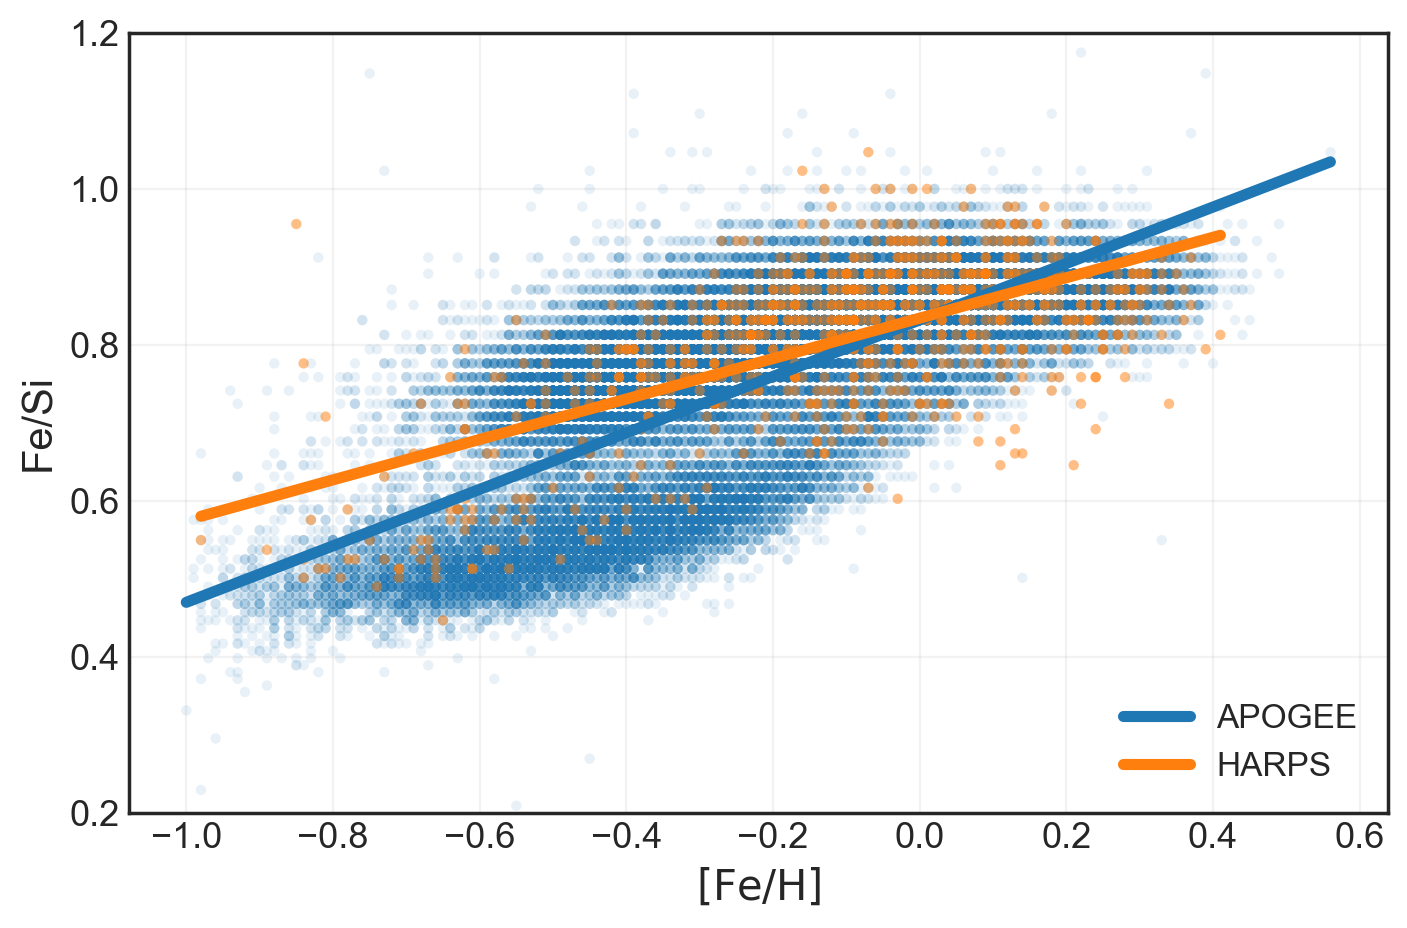

,survey,ratio_key,ratio,n_stars,intercept,intercept_err,slope,slope_err,rms_scatter,r,equation
0,APOGEE,fe_si,Fe/Si,45727,0.831904,0.000459,0.362156,0.001447,0.090256,0.721974,y = (0.8319 +/- 0.0005) + (0.3622 +/- 0.0014) ...
1,HARPS,fe_si,Fe/Si,798,0.834257,0.002663,0.259318,0.013200,0.079132,0.647654,y = (0.8343 +/- 0.0027) + (0.2593 +/- 0.0132) ...


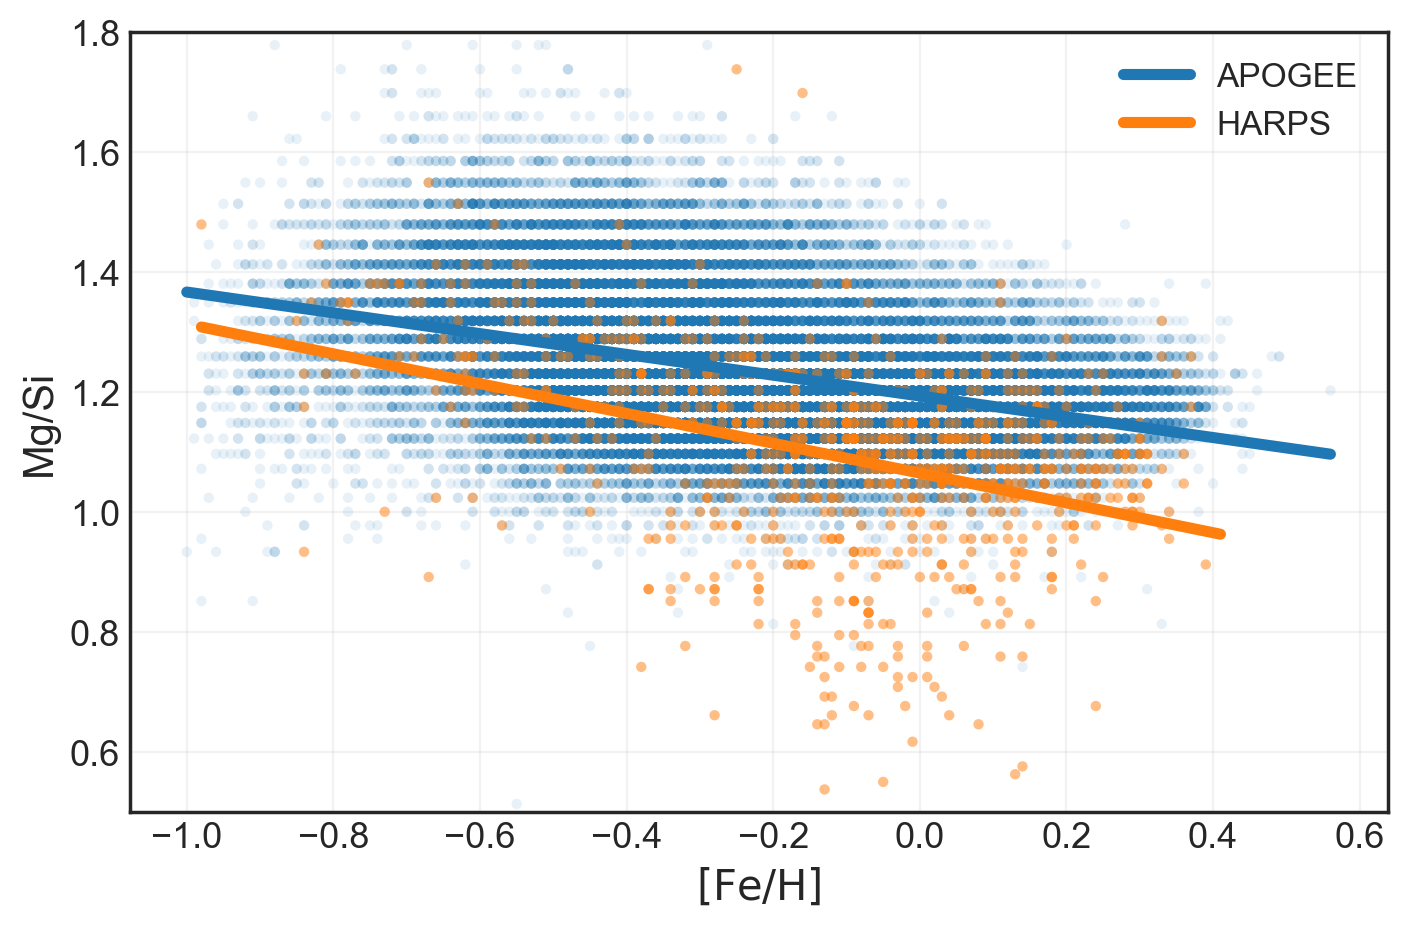

,survey,ratio_key,ratio,n_stars,intercept,intercept_err,slope,slope_err,rms_scatter,r,equation
0,APOGEE,mg_si,Mg/Si,45727,1.193080,0.000580,-0.173297,0.001853,0.109115,-0.381728,y = (1.1931 +/- 0.0006) + (-0.1733 +/- 0.0019)...
1,HARPS,mg_si,Mg/Si,798,1.064514,0.005938,-0.248558,0.018305,0.151094,-0.392465,y = (1.0645 +/- 0.0059) + (-0.2486 +/- 0.0183)...


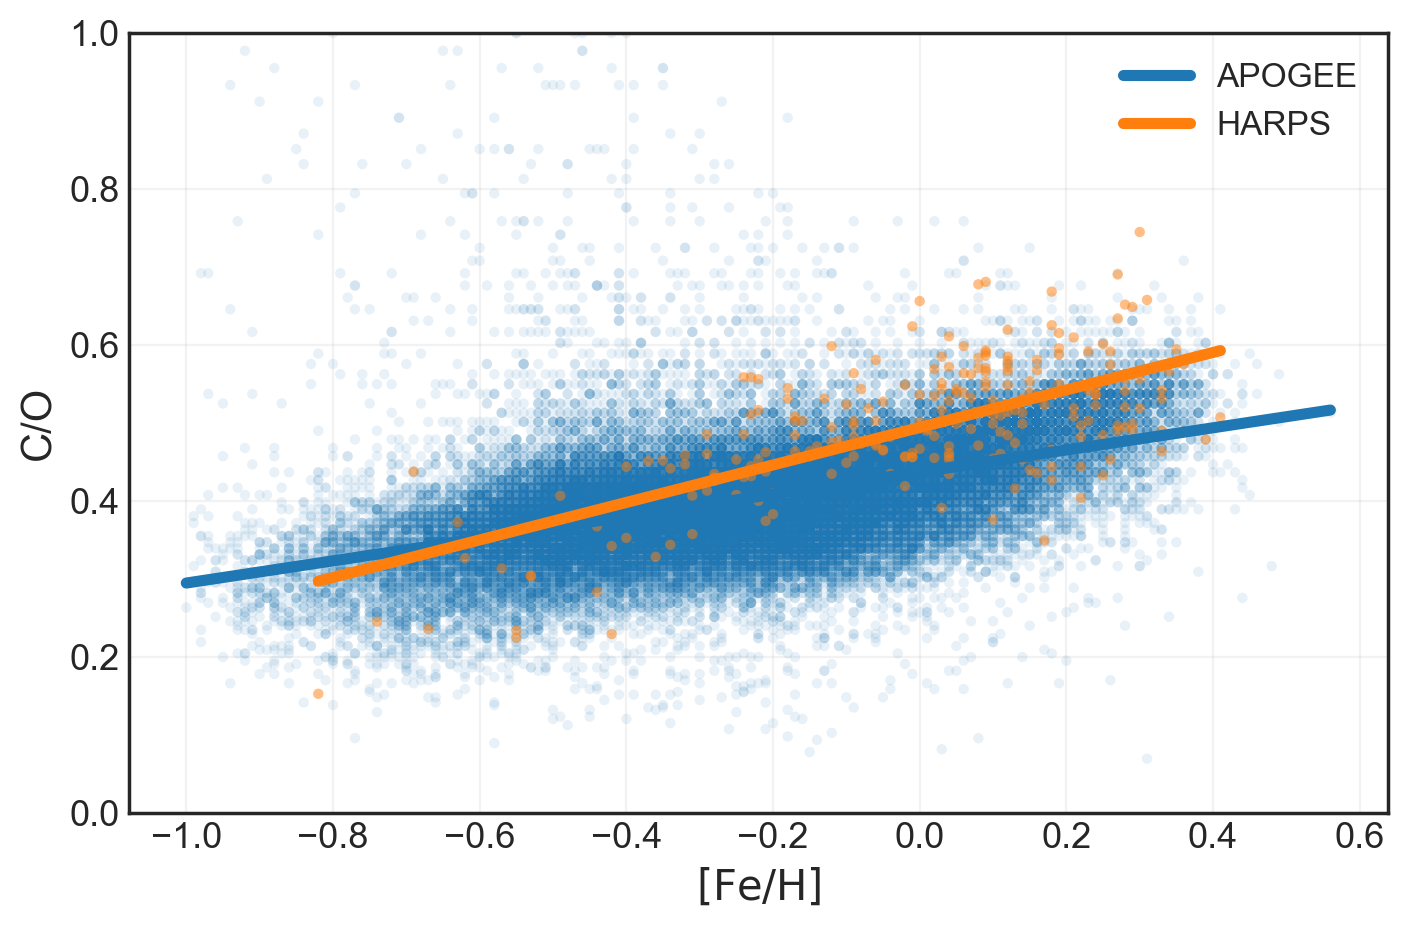

,survey,ratio_key,ratio,n_stars,intercept,intercept_err,slope,slope_err,rms_scatter,r,equation
0,APOGEE,c_o,C/O,45727,0.436725,0.000388,0.142235,0.001567,0.072651,0.453696,y = (0.4367 +/- 0.0004) + (0.1422 +/- 0.0016) ...
1,HARPS,c_o,C/O,232,0.494051,0.004588,0.240467,0.022472,0.065655,0.668159,y = (0.4941 +/- 0.0046) + (0.2405 +/- 0.0225) ...


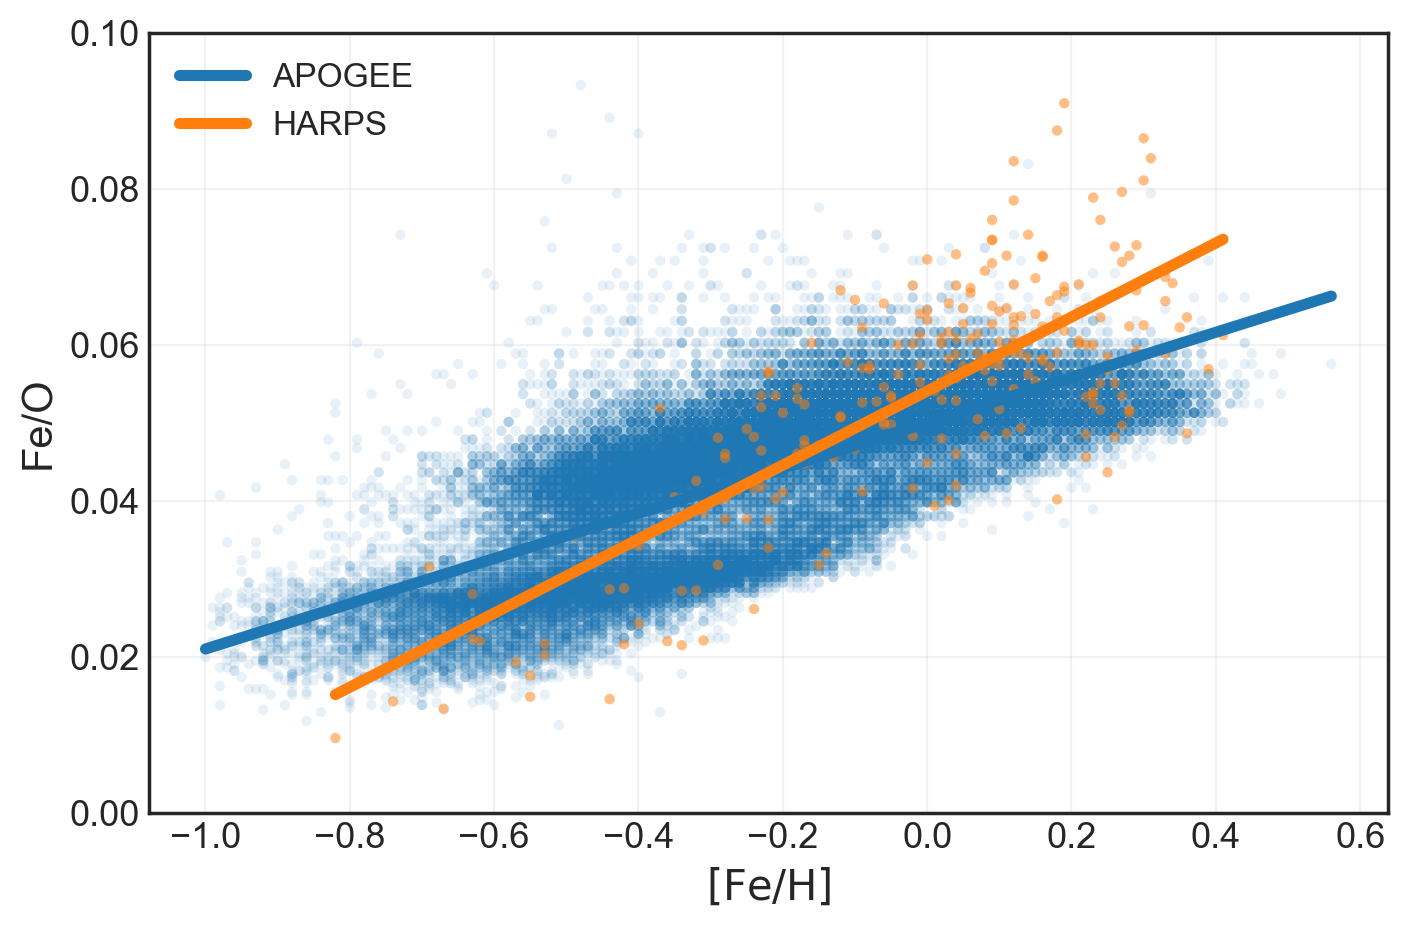

,survey,ratio_key,ratio,n_stars,intercept,intercept_err,slope,slope_err,rms_scatter,r,equation
0,APOGEE,fe_o,Fe/O,45727,0.050006,0.000038,0.029014,0.000116,0.007163,0.725247,y = (0.0500 +/- 0.0000) + (0.0290 +/- 0.0001) ...
1,HARPS,fe_o,Fe/O,232,0.054072,0.000626,0.047482,0.002730,0.009476,0.775559,y = (0.0541 +/- 0.0006) + (0.0475 +/- 0.0027) ...


,survey,ratio_key,ratio,n_stars,intercept,intercept_err,slope,slope_err,rms_scatter,r,equation
0,APOGEE,fe_si,Fe/Si,45727,0.831904,0.000459,0.362156,0.001447,0.090256,0.721974,y = (0.8319 +/- 0.0005) + (0.3622 +/- 0.0014) ...
1,HARPS,fe_si,Fe/Si,798,0.834257,0.002663,0.259318,0.013200,0.079132,0.647654,y = (0.8343 +/- 0.0027) + (0.2593 +/- 0.0132) ...
2,APOGEE,mg_si,Mg/Si,45727,1.193080,0.000580,-0.173297,0.001853,0.109115,-0.381728,y = (1.1931 +/- 0.0006) + (-0.1733 +/- 0.0019)...
3,HARPS,mg_si,Mg/Si,798,1.064514,0.005938,-0.248558,0.018305,0.151094,-0.392465,y = (1.0645 +/- 0.0059) + (-0.2486 +/- 0.0183)...
4,APOGEE,c_o,C/O,45727,0.436725,0.000388,0.142235,0.001567,0.072651,0.453696,y = (0.4367 +/- 0.0004) + (0.1422 +/- 0.0016) ...
5,HARPS,c_o,C/O,232,0.494051,0.004588,0.240467,0.022472,0.065655,0.668159,y = (0.4941 +/- 0.0046) + (0.2405 +/- 0.0225) ...
6,APOGEE,fe_o,Fe/O,45727,0.050006,0.000038,0.029014,0.000116,0.007163,0.725247,y = (0.0500 +/- 0.0000) + (0.0290 +/- 0.0001) ...
7,HARPS,fe_o,Fe/O,232,0.054072,0.000626,0.047482,0.002730,0.009476,0.775559,y = (0.0541 +/- 0.0006) + (0.0475 +/- 0.0027) ...


In [26]:
linear_results = []
for ratio_key in RATIO_SPECS:
    result = plot_ratio_fits(apogee, harps, ratio_key=ratio_key)
    display(result)
    linear_results.append(result)

linear_summary = pd.concat(linear_results, ignore_index=True)
linear_summary


## Summary table

In [27]:
linear_summary_round = linear_summary.copy()
for col in ["intercept", "intercept_err", "slope", "slope_err", "rms_scatter", "r"]:
    linear_summary_round[col] = linear_summary_round[col].round(4)

display(linear_summary_round[[
    "survey", "ratio", "n_stars", "intercept", "intercept_err", "slope", "slope_err", "rms_scatter", "r", "equation"
]])


,survey,ratio,n_stars,intercept,intercept_err,slope,slope_err,rms_scatter,r,equation
0,APOGEE,Fe/Si,45727,0.8319,0.0005,0.3622,0.0014,0.0903,0.7220,y = (0.8319 +/- 0.0005) + (0.3622 +/- 0.0014) ...
1,HARPS,Fe/Si,798,0.8343,0.0027,0.2593,0.0132,0.0791,0.6477,y = (0.8343 +/- 0.0027) + (0.2593 +/- 0.0132) ...
2,APOGEE,Mg/Si,45727,1.1931,0.0006,-0.1733,0.0019,0.1091,-0.3817,y = (1.1931 +/- 0.0006) + (-0.1733 +/- 0.0019)...
3,HARPS,Mg/Si,798,1.0645,0.0059,-0.2486,0.0183,0.1511,-0.3925,y = (1.0645 +/- 0.0059) + (-0.2486 +/- 0.0183)...
4,APOGEE,C/O,45727,0.4367,0.0004,0.1422,0.0016,0.0727,0.4537,y = (0.4367 +/- 0.0004) + (0.1422 +/- 0.0016) ...
5,HARPS,C/O,232,0.4941,0.0046,0.2405,0.0225,0.0657,0.6682,y = (0.4941 +/- 0.0046) + (0.2405 +/- 0.0225) ...
6,APOGEE,Fe/O,45727,0.0500,0.0000,0.0290,0.0001,0.0072,0.7252,y = (0.0500 +/- 0.0000) + (0.0290 +/- 0.0001) ...
7,HARPS,Fe/O,232,0.0541,0.0006,0.0475,0.0027,0.0095,0.7756,y = (0.0541 +/- 0.0006) + (0.0475 +/- 0.0027) ...


## Predicted ratios at selected [Fe/H]

In [28]:
FEH_EVAL_VALUES = [-1.0, 0.0, 0.5]

prediction_rows = []
for _, row in linear_summary.iterrows():
    for fe_h_value in FEH_EVAL_VALUES:
        predicted_ratio = row["intercept"] + row["slope"] * fe_h_value
        prediction_rows.append({
            "survey": row["survey"],
            "ratio": row["ratio"],
            "fe_h": fe_h_value,
            "predicted_ratio": predicted_ratio,
        })

predicted_ratios = pd.DataFrame(prediction_rows)
predicted_ratios_round = predicted_ratios.copy()
predicted_ratios_round["predicted_ratio"] = predicted_ratios_round["predicted_ratio"].round(4)
display(predicted_ratios_round)

predicted_ratio_comparison = (
    predicted_ratios
    .pivot(index=["ratio", "fe_h"], columns="survey", values="predicted_ratio")
    .reset_index()
)
predicted_ratio_comparison["difference"] = predicted_ratio_comparison["APOGEE"] - predicted_ratio_comparison["HARPS"]
predicted_ratio_comparison["mean_ratio"] = 0.5 * (predicted_ratio_comparison["APOGEE"] + predicted_ratio_comparison["HARPS"])
predicted_ratio_comparison["relative_difference"] = predicted_ratio_comparison["difference"] / predicted_ratio_comparison["mean_ratio"]

predicted_ratio_comparison_round = predicted_ratio_comparison.copy()
for col in ["APOGEE", "HARPS", "difference", "mean_ratio", "relative_difference"]:
    predicted_ratio_comparison_round[col] = predicted_ratio_comparison_round[col].round(4)

display(predicted_ratio_comparison_round)


,survey,ratio,fe_h,predicted_ratio
0,APOGEE,Fe/Si,-1.0,0.4697
1,APOGEE,Fe/Si,0.0,0.8319
2,APOGEE,Fe/Si,0.5,1.0130
3,HARPS,Fe/Si,-1.0,0.5749
4,HARPS,Fe/Si,0.0,0.8343
5,HARPS,Fe/Si,0.5,0.9639
6,APOGEE,Mg/Si,-1.0,1.3664
7,APOGEE,Mg/Si,0.0,1.1931
8,APOGEE,Mg/Si,0.5,1.1064
9,HARPS,Mg/Si,-1.0,1.3131


survey,ratio,fe_h,APOGEE,HARPS,difference,mean_ratio,relative_difference
0,C/O,-1.0,0.2945,0.2536,0.0409,0.2740,0.1493
1,C/O,0.0,0.4367,0.4941,-0.0573,0.4654,-0.1232
2,C/O,0.5,0.5078,0.6143,-0.1064,0.5611,-0.1897
3,Fe/O,-1.0,0.0210,0.0066,0.0144,0.0138,1.0443
4,Fe/O,0.0,0.0500,0.0541,-0.0041,0.0520,-0.0781
5,Fe/O,0.5,0.0645,0.0778,-0.0133,0.0712,-0.1869
6,Fe/Si,-1.0,0.4697,0.5749,-0.1052,0.5223,-0.2014
7,Fe/Si,0.0,0.8319,0.8343,-0.0024,0.8331,-0.0028
8,Fe/Si,0.5,1.0130,0.9639,0.0491,0.9884,0.0496
9,Mg/Si,-1.0,1.3664,1.3131,0.0533,1.3397,0.0398


In [29]:
linear_summary.to_csv(OUTPUT_DIR / "linear_ratio_fit_summary.csv", index=False)
predicted_ratios.to_csv(OUTPUT_DIR / "linear_ratio_predictions_at_selected_feh.csv", index=False)
predicted_ratio_comparison.to_csv(OUTPUT_DIR / "linear_ratio_prediction_comparison_at_selected_feh.csv", index=False)

print(f"Saved figures and summary tables to: {OUTPUT_DIR.resolve()}")


Saved figures and summary tables to: C:\Users\adbva\IA\AbundanceML\figures\ratio_fits


In [30]:
np.log10(0.2)

np.float64(-0.6989700043360187)